# Confidence, Entropy, and Decision-Margin Analysis

In [1]:
# 1. IMPORTS
import gc
import hashlib
import importlib.util
import os
import sys
import warnings
from collections import Counter
from typing import Dict, List, Optional, Tuple

import joblib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.sparse import csr_matrix, issparse
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

try:
    from IPython.display import display
except ImportError:
    display = print

print("✅ Libraries loaded.")

✅ Libraries loaded.


In [2]:
# 2. CONFIGURATION
PATH_FILE = ""  # local; ubah jika root proyek berada di lokasi lain

# Input lama tetap berada pada artifacts/<komposisi>/...
INPUT_ROOT = os.path.join(PATH_FILE, "artifacts")

# Output baru dibuat flat, tetapi tetap dipisahkan image dan docs.
OUTPUT_ROOT = os.path.join(
    PATH_FILE,
    "artifacts",
    "entropy_margin_conf",
)
OUTPUT_IMAGE_DIR = os.path.join(OUTPUT_ROOT, "image")
OUTPUT_DOCS_DIR = os.path.join(OUTPUT_ROOT, "docs")

# Lokasi dataset, features.py, dan cache tidak diubah.
DATASET_PATH = os.path.join(
    "..",
    PATH_FILE,
    "dataset",
    "shami_preprocessed_dataset_raw.csv",
)
FEATURES_PATH = os.path.join(PATH_FILE, "features.py")
CACHE_ROOT = os.path.join(PATH_FILE, "cache")
GLOBAL_SAVE_DIR = os.path.join(INPUT_ROOT, "output")

KOMPOSISI_LIST = [
    "lightgbm_original",
    "lightgbm_smote",
    "lightgbm_knsmote",
    "lightgbm_dbscansmote",
    "lightgbm_balanced_weighted",
    "lightgbm_astra_radiant",
    "xgboost_original",
    "xgboost_smote",
    "xgboost_knsmote",
    "xgboost_dbscansmote",
    "xgboost_balanced_weighted",
    "xgboost_astra_radiant",
]

RANDOM_STATE = 42
TEST_SIZE = 0.25
VALIDATION_SIZE = 0.20

# Feature configuration harus sama dengan eksperimen/model.
CHI2_PCT = 0.015
MI_PCT23 = 0.010
MI_PCT45 = 0.015
USE_OOF_INTERACTION = True
USE_SVD = False
DROP_LIST = []

# THEME
PALETTE = ["#2D4A7A", "#4A90C4", "#6DB8A8", "#C4956A"]
BG_COLOR = "#F8F9FB"
CARD_COLOR = "#FFFFFF"
TEXT_DARK = "#1A2640"
TEXT_MID = "#4A5568"
TEXT_LIGHT = "#8A97AA"
GRID_COLOR = "#E8ECF1"

for directory in [OUTPUT_ROOT, OUTPUT_IMAGE_DIR, OUTPUT_DOCS_DIR]:
    os.makedirs(directory, exist_ok=True)

print("Input root   :", INPUT_ROOT)
print("Dataset      :", DATASET_PATH)
print("Feature cache:", CACHE_ROOT)
print("Output image :", OUTPUT_IMAGE_DIR)
print("Output docs  :", OUTPUT_DOCS_DIR)

Input root   : artifacts
Dataset      : ../dataset/shami_preprocessed_dataset_raw.csv
Feature cache: cache
Output image : artifacts/entropy_margin_conf/image
Output docs  : artifacts/entropy_margin_conf/docs


In [3]:
# 3. ENVIRONMENT, STYLE, AND BASIC HELPERS
def initialize_environment():
    os.environ["PYTHONWARNINGS"] = "ignore"
    warnings.simplefilter("ignore")
    warnings.filterwarnings("ignore")
    warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
    warnings.filterwarnings("ignore", module="sklearn.utils.validation")
    warnings.filterwarnings("ignore", message="X does not have valid feature names")


def set_global_style():
    plt.rcParams.update({
        "figure.facecolor": BG_COLOR,
        "axes.facecolor": CARD_COLOR,
        "axes.edgecolor": GRID_COLOR,
        "axes.linewidth": 0.8,
        "axes.grid": True,
        "grid.color": GRID_COLOR,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.8,
        "text.color": TEXT_DARK,
        "axes.labelcolor": TEXT_MID,
        "xtick.color": TEXT_MID,
        "ytick.color": TEXT_MID,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "font.family": "sans-serif",
        "axes.spines.top": False,
        "axes.spines.right": False,
    })
    print("✅ Global style set.")


def load_features_module():
    if not os.path.exists(FEATURES_PATH):
        raise FileNotFoundError(
            f"features.py tidak ditemukan: {FEATURES_PATH}"
        )

    spec = importlib.util.spec_from_file_location("features", FEATURES_PATH)
    module = importlib.util.module_from_spec(spec)
    sys.modules["features"] = module
    spec.loader.exec_module(module)

    print("Features file   :", module.__file__)
    print("Features version:", getattr(module, "FEATURES_VERSION", "unknown"))
    return module


DIALECT_MAP = {
    "Jordan": "Yordania",
    "Yordania": "Yordania",
    "Lebanon": "Lebanon",
    "Palestine": "Palestina",
    "Palestina": "Palestina",
    "Syria": "Suriah",
    "Suriah": "Suriah",
}


def canonical_dialect(value):
    return DIALECT_MAP.get(str(value).strip(), str(value).strip())


def convert_correct_column(df):
    df = df.copy()
    if "correct" not in df.columns:
        return df
    if df["correct"].dtype == bool:
        return df

    converted = (
        df["correct"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )

    if converted.isna().any():
        bad = df.loc[converted.isna(), "correct"].drop_duplicates().tolist()
        raise ValueError(f"Nilai kolom correct tidak dikenali: {bad}")

    df["correct"] = converted.astype(bool)
    return df


def save_and_show(name, image_dir=OUTPUT_IMAGE_DIR):
    path = os.path.join(image_dir, f"{name}.png")
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"🖼️ Saved: {path}")
    plt.show()
    plt.close()


def get_csv_paths(directory, komposisi):
    return (
        os.path.join(directory, f"{komposisi}_error_analysis_full.csv"),
        os.path.join(directory, f"{komposisi}_error_analysis_errors_only.csv"),
    )


def csv_pair_exists(directory, komposisi):
    full_path, errors_path = get_csv_paths(directory, komposisi)
    return os.path.exists(full_path) and os.path.exists(errors_path)


initialize_environment()
set_global_style()

✅ Global style set.


In [ ]:
# 4. PREPARE IDENTICAL TEST DATA AND FEATURE MATRIX
#    Fungsi ini hanya dipanggil jika ada CSV yang belum tersedia.
def build_block_slices(block_sizes):
    slices = {}
    start = 0
    for name, size in block_sizes.items():
        slices[name] = (start, start + size)
        start += size
    return slices


def drop_blocks(X, block_slices, drop_list):
    keep_columns = []
    for name, (start, end) in block_slices.items():
        if name not in drop_list:
            keep_columns.extend(range(start, end))
        else:
            print(f"  Dropping block: {name}, size={end-start:,}")
    keep_columns = np.asarray(keep_columns)
    return X[:, keep_columns], keep_columns


def prepare_analysis_context(features_module):
    if not os.path.exists(DATASET_PATH):
        raise FileNotFoundError(f"Dataset tidak ditemukan: {DATASET_PATH}")

    clean_noise = features_module.clean_noise
    clean_char = features_module.clean_char
    ShamiFeatureExtractor = features_module.ShamiFeatureExtractor

    df = pd.read_csv(DATASET_PATH)
    df = (
        df.dropna(subset=["text", "label"])
          .rename(columns={"label": "country"})
          .copy()
    )
    df["clean_word"] = df["text"].apply(clean_noise)
    df["clean_char"] = df["text"].apply(clean_char)

    X = df[["text", "clean_word", "clean_char"]]

    # Gunakan encoder tersimpan jika tersedia agar ID kelas identik dengan model.
    encoder_path = os.path.join(GLOBAL_SAVE_DIR, "label_encoder.pkl")
    if os.path.exists(encoder_path):
        le = joblib.load(encoder_path)
        print("✅ Loading saved label encoder:", encoder_path)

        encoder_class_by_canonical = {
            canonical_dialect(label): label for label in le.classes_
        }

        def to_encoder_label(value):
            canonical = canonical_dialect(value)
            if canonical not in encoder_class_by_canonical:
                raise ValueError(
                    f"Label {value!r} tidak ditemukan dalam saved label encoder."
                )
            return encoder_class_by_canonical[canonical]

        y_for_encoder = df["country"].apply(to_encoder_label)
        y_encoded = le.transform(y_for_encoder)
    else:
        print("⚠️ Saved label encoder tidak ditemukan; fitting dari label dataset.")
        le = LabelEncoder()
        y_encoded = le.fit_transform(df["country"])

    label_names = np.asarray(le.classes_)
    print("Label mapping:")
    for class_id, label in enumerate(label_names):
        print(f"  {class_id}: {label} → {canonical_dialect(label)}")

    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X,
        y_encoded,
        test_size=TEST_SIZE,
        stratify=y_encoded,
        random_state=RANDOM_STATE,
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full,
        y_train_full,
        test_size=VALIDATION_SIZE,
        stratify=y_train_full,
        random_state=RANDOM_STATE,
    )

    split_hash = hashlib.md5(
        pd.util.hash_pandas_object(X_train["text"]).values.tobytes()
    ).hexdigest()[:10]
    base_signature = f"{getattr(features_module, 'FEATURES_VERSION', 'v1')}_{split_hash}"
    base_cache_dir = os.path.join(CACHE_ROOT, base_signature)
    os.makedirs(base_cache_dir, exist_ok=True)

    feature_cache_key = (
        f"chi2_{CHI2_PCT}_mi23_{MI_PCT23}_mi45_{MI_PCT45}"
        f"_oof_inter_{int(USE_OOF_INTERACTION)}"
    )
    data_hash = hashlib.md5(df["text"].str.cat().encode()).hexdigest()[:8]
    feature_cache_dir = os.path.join(
        base_cache_dir,
        feature_cache_key,
        data_hash,
    )
    os.makedirs(feature_cache_dir, exist_ok=True)

    print("Base signature :", base_signature)
    print("Feature cache  :", feature_cache_dir)

    feature_extractor_path = os.path.join(
        base_cache_dir,
        "feature_extractor.pkl",
    )
    if os.path.exists(feature_extractor_path):
        print("✅ Loading base feature extractor...")
        feat = joblib.load(feature_extractor_path)
    else:
        print("⚙️ Building base feature extractor...")
        feat = ShamiFeatureExtractor(
            chi2_pct=CHI2_PCT,
            mi_pct23=MI_PCT23,
            mi_pct45=MI_PCT45,
            use_oof_lr=True,
            use_oof_interaction=USE_OOF_INTERACTION,
        )
        feat.fit(X_train, y_train)
        joblib.dump(feat, feature_extractor_path)

    feat.update_chi2_pct(CHI2_PCT)
    feat.update_mi_pct(new_pct23=MI_PCT23, new_pct45=MI_PCT45)

    xtr_path = os.path.join(feature_cache_dir, "Xtr_feat.pkl")
    xval_path = os.path.join(feature_cache_dir, "Xval_feat.pkl")
    xte_path = os.path.join(feature_cache_dir, "Xte_feat.pkl")
    ytr_path = os.path.join(feature_cache_dir, "y_train.pkl")
    yval_path = os.path.join(feature_cache_dir, "y_val.pkl")
    yte_path = os.path.join(feature_cache_dir, "y_test.pkl")

    matrix_paths = [
        xtr_path, xval_path, xte_path,
        ytr_path, yval_path, yte_path,
    ]

    if all(os.path.exists(path) for path in matrix_paths):
        print("✅ Loading feature matrices from cache...")
        Xtr_feat = joblib.load(xtr_path)
        Xval_feat = joblib.load(xval_path)
        Xte_feat = joblib.load(xte_path)
        y_train_cached = np.asarray(joblib.load(ytr_path)).reshape(-1)
        y_val_cached = np.asarray(joblib.load(yval_path)).reshape(-1)
        y_test_cached = np.asarray(joblib.load(yte_path)).reshape(-1)

        # Jangan memasangkan feature cache dengan split yang berbeda.
        if not np.array_equal(np.asarray(y_test).reshape(-1), y_test_cached):
            raise AssertionError(
                "y_test cache tidak sama dengan split saat ini. "
                "Periksa label encoder, dataset, dan parameter split."
            )
        y_train = y_train_cached
        y_val = y_val_cached
        y_test = y_test_cached
    else:
        print("⚙️ Building feature matrices...")
        Xtr_feat = feat.transform(X_train, is_train=True)
        Xval_feat = feat.transform(X_val, is_train=False)
        Xte_feat = feat.transform(X_test, is_train=False)
        gc.collect()

        joblib.dump(Xtr_feat, xtr_path)
        joblib.dump(Xval_feat, xval_path)
        joblib.dump(Xte_feat, xte_path)
        joblib.dump(y_train, ytr_path)
        joblib.dump(y_val, yval_path)
        joblib.dump(y_test, yte_path)

    if DROP_LIST:
        block_slices = build_block_slices(feat.block_sizes)
        Xtr_sel, _ = drop_blocks(Xtr_feat, block_slices, DROP_LIST)
        Xval_sel, _ = drop_blocks(Xval_feat, block_slices, DROP_LIST)
        Xte_sel, kept_columns = drop_blocks(Xte_feat, block_slices, DROP_LIST)
    else:
        Xtr_sel = Xtr_feat
        Xval_sel = Xval_feat
        Xte_sel = Xte_feat
        kept_columns = np.arange(Xtr_feat.shape[1])

    if USE_SVD:
        from sklearn.decomposition import TruncatedSVD
        print("Applying SVD compression...")
        svd = TruncatedSVD(n_components=200, random_state=RANDOM_STATE)
        Xtr_sel = svd.fit_transform(Xtr_sel)
        Xval_sel = svd.transform(Xval_sel)
        Xte_sel = svd.transform(Xte_sel)

    if Xte_sel.shape[0] != len(X_test):
        raise AssertionError(
            f"Xte_sel dan X_test tidak sejajar: {Xte_sel.shape[0]} != {len(X_test)}"
        )

    print("Train shape:", Xtr_sel.shape)
    print("Val shape  :", Xval_sel.shape)
    print("Test shape :", Xte_sel.shape)

    return {
        "X_test": X_test.copy(),
        "Xte_sel": Xte_sel,
        "y_test": np.asarray(y_test).reshape(-1),
        "label_names": label_names,
    }

In [ ]:
# 5. LOAD CSV OR BUILD IT FROM THE TRAINED MODEL
def load_csv_pair(directory, komposisi):
    full_path, errors_path = get_csv_paths(directory, komposisi)
    df_export = convert_correct_column(pd.read_csv(full_path))
    df_errors = convert_correct_column(pd.read_csv(errors_path))
    return df_export, df_errors


def validate_analysis_dataframe(df_export, komposisi):
    required = {
        "true_label",
        "pred_label",
        "correct",
        "confidence",
        "entropy",
        "margin",
        "error_category",
    }
    missing = required - set(df_export.columns)
    if missing:
        raise ValueError(
            f"[{komposisi}] kolom error-analysis belum lengkap: {sorted(missing)}"
        )


def predict_trained_model(model, algorithm, X_matrix):
    if algorithm == "xgboost" and issparse(X_matrix):
        X_input = csr_matrix(X_matrix, dtype=np.float32)
    else:
        X_input = X_matrix

    if algorithm == "lightgbm":
        best_iteration = getattr(model, "best_iteration_", None)
        if best_iteration is not None and best_iteration > 0:
            probabilities = model.predict_proba(
                X_input,
                num_iteration=best_iteration,
            )
            predictions = model.predict(
                X_input,
                num_iteration=best_iteration,
            )
        else:
            probabilities = model.predict_proba(X_input)
            predictions = model.predict(X_input)
    elif algorithm == "xgboost":
        probabilities = model.predict_proba(X_input)
        predictions = model.predict(X_input)
    else:
        raise ValueError(f"Algoritma tidak dikenali: {algorithm}")

    return np.asarray(predictions).astype(int), np.asarray(probabilities)


def build_error_analysis_from_model(
    model_dir,
    komposisi,
    analysis_context,
):
    if analysis_context is None:
        raise RuntimeError(
            f"[{komposisi}] analysis_context tidak tersedia."
        )

    model_path = os.path.join(model_dir, f"model_{komposisi}.pkl")
    if not os.path.exists(model_path):
        print(f"[SKIP] Model tidak ditemukan: {model_path}")
        return None, None

    print("📦 Loading trained model:", model_path)
    model = joblib.load(model_path)

    X_test = analysis_context["X_test"]
    Xte_sel = analysis_context["Xte_sel"]
    y_test = np.asarray(analysis_context["y_test"]).reshape(-1)
    label_names = np.asarray(analysis_context["label_names"])

    expected_features = getattr(model, "n_features_in_", None)
    if expected_features is not None and expected_features != Xte_sel.shape[1]:
        raise ValueError(
            f"[{komposisi}] dimensi fitur tidak cocok: "
            f"model={expected_features}, Xte_sel={Xte_sel.shape[1]}"
        )

    if len(X_test) != Xte_sel.shape[0] or len(X_test) != len(y_test):
        raise ValueError(f"[{komposisi}] test data tidak sejajar.")

    algorithm, scenario = komposisi.split("_", 1)
    predictions, probabilities = predict_trained_model(
        model,
        algorithm,
        Xte_sel,
    )

    if probabilities.shape[0] != len(y_test):
        raise ValueError(f"[{komposisi}] jumlah probabilitas tidak sesuai test set.")

    true_labels = [canonical_dialect(label_names[int(i)]) for i in y_test]
    predicted_labels = [
        canonical_dialect(label_names[int(i)]) for i in predictions
    ]
    sorted_probabilities = np.sort(probabilities, axis=1)

    df_export = pd.DataFrame({
        "sample_id": X_test.index.astype(str).values,
        "text": X_test["text"].fillna("").astype(str).values,
        "clean_word": X_test["clean_word"].fillna("").astype(str).values,
        "true_label": true_labels,
        "pred_label": predicted_labels,
        "correct": y_test == predictions,
        "confidence": np.max(probabilities, axis=1),
        "entropy": (-probabilities * np.log(probabilities + 1e-12)).sum(axis=1),
        "margin": sorted_probabilities[:, -1] - sorted_probabilities[:, -2],
        "text_len": X_test["text"].fillna("").astype(str).str.len().values,
        "n_words": (
            X_test["clean_word"]
            .fillna("")
            .astype(str)
            .str.split()
            .str.len()
            .values
        ),
        "algorithm": algorithm,
        "scenario": scenario,
    })

    def categorize_error(row):
        if row["correct"]:
            return "correct"
        if row["n_words"] <= 4:
            return "too_short_<=4w"
        if row["text_len"] < 30:
            return "too_short_<30c"
        if row["confidence"] > 0.85:
            return "high_conf_wrong"
        if row["confidence"] < 0.45:
            return "low_conf_ambiguous"
        return "medium_conf_wrong"

    df_export["error_category"] = df_export.apply(categorize_error, axis=1)
    df_errors = (
        df_export.loc[~df_export["correct"]]
        .sort_values(
            ["true_label", "pred_label", "confidence"],
            ascending=[True, True, False],
        )
        .copy()
    )

    validate_analysis_dataframe(df_export, komposisi)
    print(f"✅ Generated: {len(df_export):,} rows, {len(df_errors):,} errors")
    return df_export, df_errors


def save_canonical_csv_pair(df_export, df_errors, komposisi):
    full_path, errors_path = get_csv_paths(OUTPUT_DOCS_DIR, komposisi)
    df_export.to_csv(full_path, index=False, encoding="utf-8-sig")
    df_errors.to_csv(errors_path, index=False, encoding="utf-8-sig")
    print("📄 Saved:", full_path)
    print("📄 Saved:", errors_path)


def get_or_create_error_analysis(komposisi, analysis_context=None):
    input_docs_dir = os.path.join(INPUT_ROOT, komposisi, "docs")
    input_model_dir = os.path.join(INPUT_ROOT, komposisi, "model")

    # Prioritas 1: CSV kanonis hasil notebook ini.
    if csv_pair_exists(OUTPUT_DOCS_DIR, komposisi):
        print(f"✅ [{komposisi}] loading CSV dari output cache.")
        df_export, df_errors = load_csv_pair(OUTPUT_DOCS_DIR, komposisi)

    # Prioritas 2: CSV lama dari direktori komposisi.
    elif csv_pair_exists(input_docs_dir, komposisi):
        print(f"✅ [{komposisi}] loading existing CSV.")
        df_export, df_errors = load_csv_pair(input_docs_dir, komposisi)

    # Prioritas 3: belum ada CSV, prediksi trained model.
    else:
        print(f"⚙️ [{komposisi}] CSV belum ada; predicting trained model.")
        df_export, df_errors = build_error_analysis_from_model(
            model_dir=input_model_dir,
            komposisi=komposisi,
            analysis_context=analysis_context,
        )

        if df_export is None or df_errors is None:
            return None, None

    df_export = convert_correct_column(df_export)
    df_errors = convert_correct_column(df_errors)

    # Seragamkan label lama dan label hasil prediksi baru untuk visual/output.
    for frame in [df_export, df_errors]:
        if "true_label" in frame.columns:
            frame["true_label"] = frame["true_label"].apply(canonical_dialect)
        if "pred_label" in frame.columns:
            frame["pred_label"] = frame["pred_label"].apply(canonical_dialect)

    validate_analysis_dataframe(df_export, komposisi)

    # Semua komposisi memperoleh pasangan CSV di output yang sama.
    save_canonical_csv_pair(df_export, df_errors, komposisi)
    return df_export, df_errors

In [ ]:
# 6. CONFIDENCE, ENTROPY, AND MARGIN FUNCTIONS
def extract_boxplot_metrics(group):
    group = group.dropna()
    if len(group) == 0:
        return pd.Series({
            "Samples_(N)": 0,
            "Min_Value": np.nan,
            "Lower_Whisker": np.nan,
            "Q1_(25th)": np.nan,
            "Median_(50th)": np.nan,
            "Q3_(75th)": np.nan,
            "Upper_Whisker": np.nan,
            "Max_Value": np.nan,
            "Outliers_Count": 0,
            "Outlier_Percentage": 0.0,
        })

    q1 = group.quantile(0.25)
    median = group.median()
    q3 = group.quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    lower_candidates = group[group >= lower_limit]
    upper_candidates = group[group <= upper_limit]
    lower_whisker = lower_candidates.min() if not lower_candidates.empty else np.nan
    upper_whisker = upper_candidates.max() if not upper_candidates.empty else np.nan
    outliers = ((group < lower_limit) | (group > upper_limit)).sum()

    return pd.Series({
        "Samples_(N)": len(group),
        "Min_Value": round(group.min(), 4),
        "Lower_Whisker": round(lower_whisker, 4),
        "Q1_(25th)": round(q1, 4),
        "Median_(50th)": round(median, 4),
        "Q3_(75th)": round(q3, 4),
        "Upper_Whisker": round(upper_whisker, 4),
        "Max_Value": round(group.max(), 4),
        "Outliers_Count": int(outliers),
        "Outlier_Percentage": round(outliers / len(group) * 100, 2),
    })


def print_error_summary(df_errors):
    print("\nERROR SUMMARY")
    summary = (
        df_errors
        .groupby(["true_label", "pred_label", "error_category"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )
    print(summary.to_string(index=False))


def process_confidence(df_export, komposisi):
    print("\nGenerating Confidence Distribution...")
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG_COLOR)
    ax.set_facecolor(CARD_COLOR)

    bin_edges = np.linspace(0, 1, 36)
    histogram_rows = []
    colors = {True: "#2D4A7A", False: "#C4956A"}
    labels = {True: "Correct", False: "Wrong"}

    for correct in [True, False]:
        subset = df_export.loc[
            df_export["correct"] == correct,
            "confidence",
        ].dropna()

        counts, _ = np.histogram(subset, bins=bin_edges)
        density, _ = np.histogram(subset, bins=bin_edges, density=True)

        ax.hist(
            subset,
            bins=bin_edges,
            density=True,
            alpha=0.60,
            color=colors[correct],
            label=f"{labels[correct]} (n={len(subset):,})",
            edgecolor="white",
            linewidth=0.5,
        )

        total = len(subset)
        for index in range(len(bin_edges) - 1):
            histogram_rows.append({
                "Prediction": labels[correct],
                "Bin": index + 1,
                "Bin_Start": round(bin_edges[index], 6),
                "Bin_End": round(bin_edges[index + 1], 6),
                "Count": int(counts[index]),
                "Percentage": round(counts[index] / total * 100, 4) if total else 0,
                "Density": round(float(density[index]), 6) if total else 0,
            })

    ax.set_xlim(0, 1)
    ax.set_xlabel("Confidence Score", color=TEXT_MID)
    ax.set_ylabel("Density", color=TEXT_MID)
    ax.set_title(
        "Prediction Confidence — Correct vs Wrong",
        color=TEXT_DARK,
        fontweight="bold",
    )
    ax.legend(frameon=False)
    ax.set_axisbelow(True)
    fig.tight_layout()

    save_and_show(f"{komposisi}_confidence_distribution")

    histogram_path = os.path.join(
        OUTPUT_DOCS_DIR,
        f"{komposisi}_confidence_histogram_data.csv",
    )
    pd.DataFrame(histogram_rows).to_csv(
        histogram_path,
        index=False,
        encoding="utf-8-sig",
    )
    print("📄 Saved:", histogram_path)


def process_entropy(df_export, komposisi):
    print("\nGenerating Entropy Analysis...")
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG_COLOR)
    ax.set_facecolor(CARD_COLOR)

    dialect_order = [
        item for item in ["Yordania", "Lebanon", "Palestina", "Suriah"]
        if item in set(df_export["true_label"])
    ]

    sns.boxplot(
        data=df_export,
        x="true_label",
        y="entropy",
        order=dialect_order or None,
        palette=PALETTE,
        width=0.55,
        linewidth=1.2,
        flierprops={
            "marker": "o",
            "markerfacecolor": TEXT_LIGHT,
            "markersize": 3,
            "alpha": 0.40,
            "linestyle": "none",
        },
        ax=ax,
    )
    sns.stripplot(
        data=df_export,
        x="true_label",
        y="entropy",
        order=dialect_order or None,
        color=TEXT_LIGHT,
        alpha=0.15,
        size=2,
        jitter=True,
        ax=ax,
    )

    ax.set_xlabel("Dialect", color=TEXT_MID)
    ax.set_ylabel("Prediction Entropy", color=TEXT_MID)
    ax.set_title("Prediction Entropy per Dialect — Test Set", color=TEXT_DARK)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_and_show(f"{komposisi}_entropy_per_class")

    stats = (
        df_export
        .groupby("true_label")["entropy"]
        .apply(extract_boxplot_metrics)
        .unstack()
    )
    metrics_path = os.path.join(
        OUTPUT_DOCS_DIR,
        f"{komposisi}_entropy_exact_metrics.csv",
    )
    stats.to_csv(metrics_path, encoding="utf-8-sig")
    print("📄 Saved:", metrics_path)


def process_margin(df_export, komposisi):
    print("\nGenerating Margin Analysis...")
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG_COLOR)
    ax.set_facecolor(CARD_COLOR)

    dialect_order = [
        item for item in ["Yordania", "Lebanon", "Palestina", "Suriah"]
        if item in set(df_export["true_label"])
    ]

    sns.boxplot(
        data=df_export,
        x="true_label",
        y="margin",
        hue="correct",
        order=dialect_order or None,
        hue_order=[True, False],
        palette={True: "#2D4A7A", False: "#C4956A"},
        width=0.55,
        linewidth=1.2,
        flierprops={
            "marker": "o",
            "markerfacecolor": TEXT_LIGHT,
            "markersize": 3,
            "alpha": 0.40,
            "linestyle": "none",
        },
        ax=ax,
    )

    handles, _ = ax.get_legend_handles_labels()
    ax.legend(
        handles,
        ["Correct", "Wrong"],
        title="Prediction",
        frameon=False,
    )
    ax.set_xlabel("Dialect", color=TEXT_MID)
    ax.set_ylabel("Decision Margin", color=TEXT_MID)
    ax.set_title(
        "Decision Margin per Dialect — Correct vs Wrong",
        color=TEXT_DARK,
    )
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_and_show(f"{komposisi}_margin_analysis")

    stats = (
        df_export
        .groupby(["true_label", "correct"])["margin"]
        .apply(extract_boxplot_metrics)
        .unstack()
    )
    stats.index = pd.MultiIndex.from_tuples(
        [
            (dialect, "Correct" if prediction else "Wrong")
            for dialect, prediction in stats.index
        ],
        names=["Dialect", "Prediction"],
    )
    metrics_path = os.path.join(
        OUTPUT_DOCS_DIR,
        f"{komposisi}_margin_exact_metrics.csv",
    )
    stats.to_csv(metrics_path, encoding="utf-8-sig")
    print("📄 Saved:", metrics_path)

Features file   : features.py
Features version: Shami Extractor

CSV PREFLIGHT
⚠️ 2 komposisi belum memiliki pasangan CSV:
  - lightgbm_astra_radiant
  - xgboost_astra_radiant

⚙️ Preparing shared test data once...
✅ Loading saved label encoder: artifacts/output/label_encoder.pkl
Label mapping:
  0: Jordan → Yordania
  1: Lebanon → Lebanon
  2: Palestine → Palestina
  3: Syria → Suriah
Base signature : Shami Extractor_0890ac2785
Feature cache  : cache/Shami Extractor_0890ac2785/chi2_0.015_mi23_0.01_mi45_0.015_oof_inter_1/6ace3dc3
✅ Loading base feature extractor...
[update] chi2_pct=1.50% -> chi2_k=2,420
[update] mi_pct23=1.00% -> mi_k23=500
[update] mi_pct45=1.50% -> mi_k45=2,650
✅ Loading feature matrices from cache...
Train shape: (39748, 5644)
Val shape  : (9937, 5644)
Test shape : (16562, 5644)

Processing: lightgbm_original
✅ [lightgbm_original] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_original_error_analysis_full.csv
📄 Saved: artifacts/entropy_m

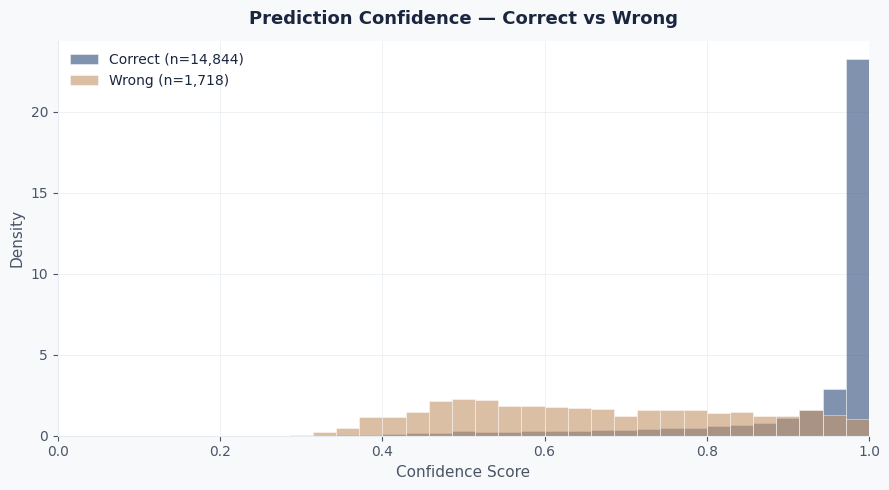

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_original_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_original_entropy_per_class.png


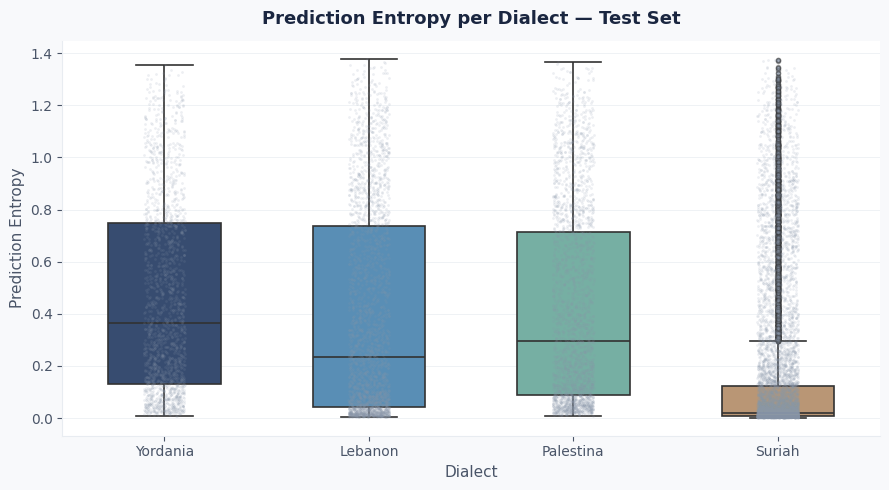

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_original_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_original_margin_analysis.png


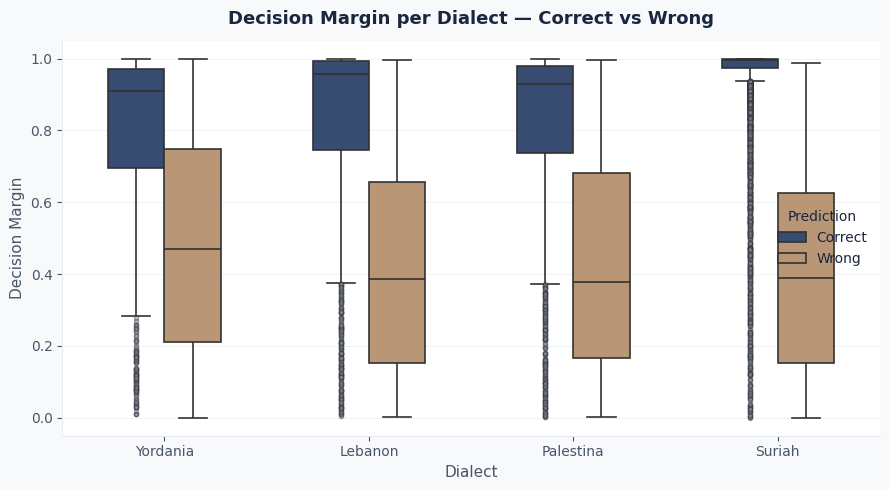

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_original_margin_exact_metrics.csv

Processing: lightgbm_smote
✅ [lightgbm_smote] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_smote_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_smote_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,720

ERROR SUMMARY
true_label pred_label     error_category  count
  Yordania  Palestina  medium_conf_wrong     81
   Lebanon     Suriah  medium_conf_wrong     74
 Palestina     Suriah  medium_conf_wrong     73
  Yordania     Suriah  medium_conf_wrong     68
    Suriah    Lebanon  medium_conf_wrong     66
   Lebanon  Palestina  medium_conf_wrong     64
    Suriah  Palestina  medium_conf_wrong     63
 Palestina   Yordania  medium_conf_wrong     54
 Palestina    Lebanon  medium_conf_wrong     52
    Suriah   Yordania  medium_conf_wrong     52
    Suriah    Lebanon     too_short_<=4w     47
   Lebanon     Suriah     too_s

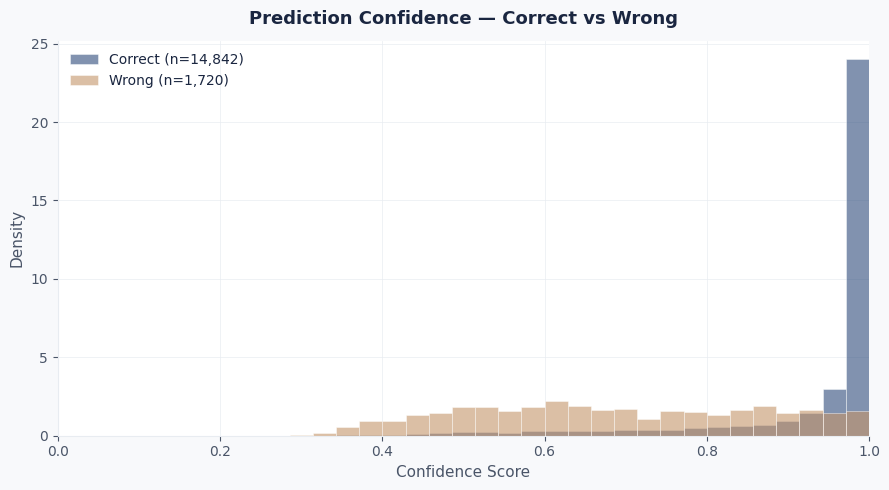

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_smote_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_smote_entropy_per_class.png


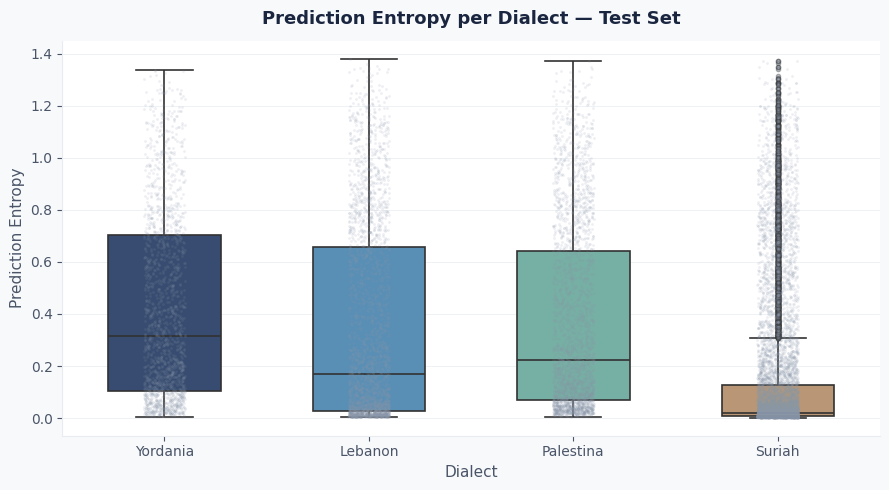

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_smote_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_smote_margin_analysis.png


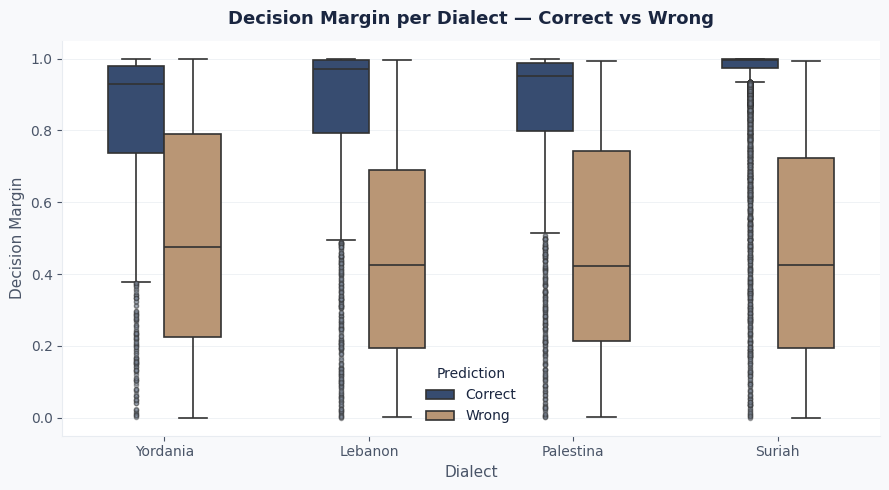

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_smote_margin_exact_metrics.csv

Processing: lightgbm_knsmote
✅ [lightgbm_knsmote] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_knsmote_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_knsmote_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,724

ERROR SUMMARY
true_label pred_label     error_category  count
  Yordania  Palestina  medium_conf_wrong     80
   Lebanon     Suriah  medium_conf_wrong     80
 Palestina     Suriah  medium_conf_wrong     77
 Palestina    Lebanon  medium_conf_wrong     70
    Suriah  Palestina  medium_conf_wrong     63
    Suriah    Lebanon  medium_conf_wrong     61
  Yordania     Suriah  medium_conf_wrong     60
   Lebanon     Suriah     too_short_<=4w     57
   Lebanon  Palestina  medium_conf_wrong     54
 Palestina   Yordania  medium_conf_wrong     52
  Yordania  Palestina    high_conf_wrong     49
    Suriah   Yordania  med

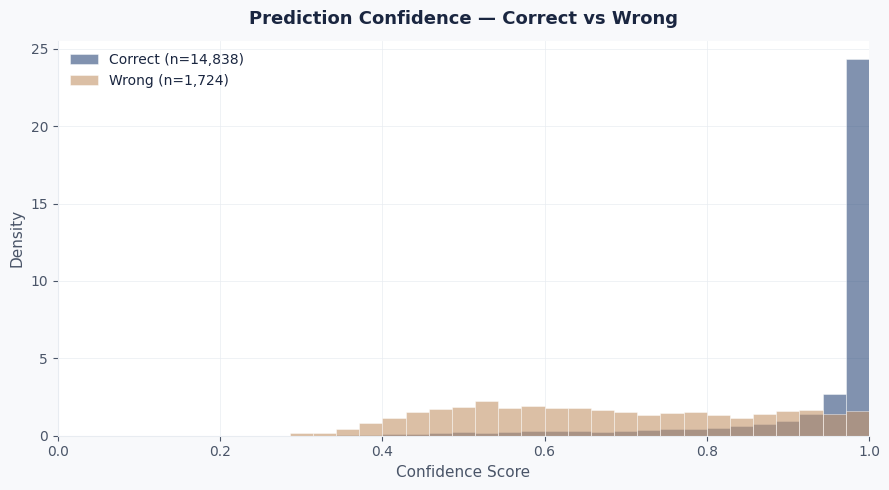

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_knsmote_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_knsmote_entropy_per_class.png


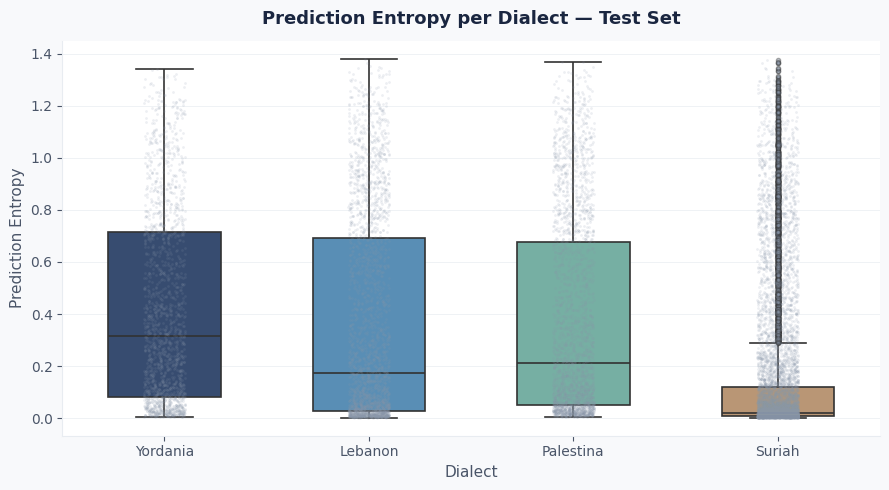

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_knsmote_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_knsmote_margin_analysis.png


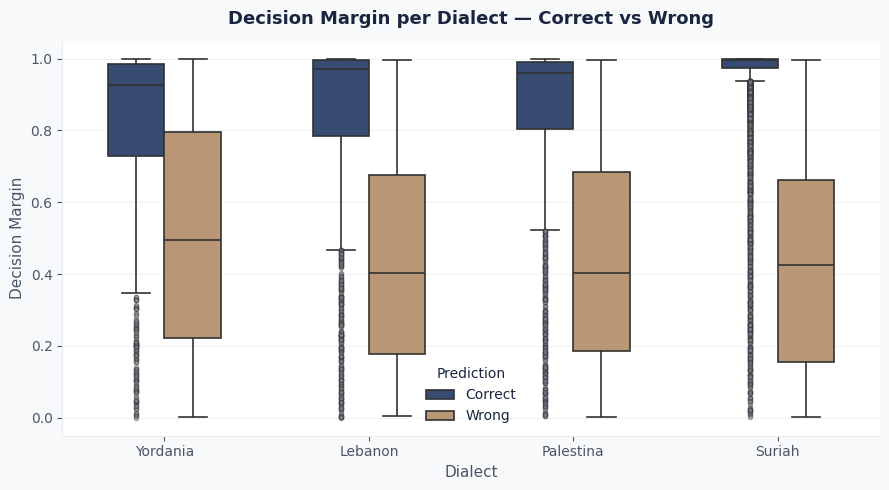

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_knsmote_margin_exact_metrics.csv

Processing: lightgbm_dbscansmote
✅ [lightgbm_dbscansmote] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_dbscansmote_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_dbscansmote_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,700

ERROR SUMMARY
true_label pred_label     error_category  count
  Yordania  Palestina  medium_conf_wrong     89
 Palestina     Suriah  medium_conf_wrong     79
   Lebanon     Suriah  medium_conf_wrong     75
 Palestina    Lebanon  medium_conf_wrong     70
    Suriah  Palestina  medium_conf_wrong     68
    Suriah    Lebanon  medium_conf_wrong     64
  Yordania     Suriah  medium_conf_wrong     60
 Palestina   Yordania  medium_conf_wrong     59
   Lebanon  Palestina  medium_conf_wrong     59
   Lebanon     Suriah     too_short_<=4w     57
    Suriah   Yordania  medium_conf_wrong     47
 Palesti

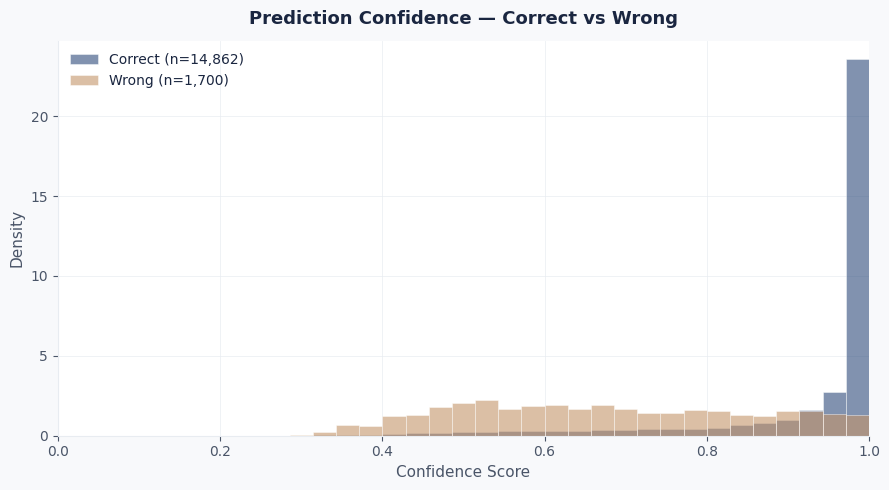

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_dbscansmote_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_dbscansmote_entropy_per_class.png


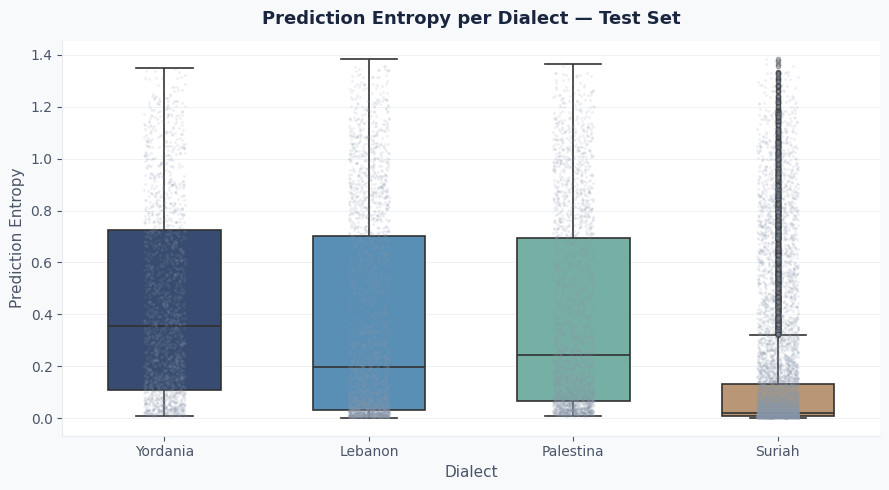

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_dbscansmote_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_dbscansmote_margin_analysis.png


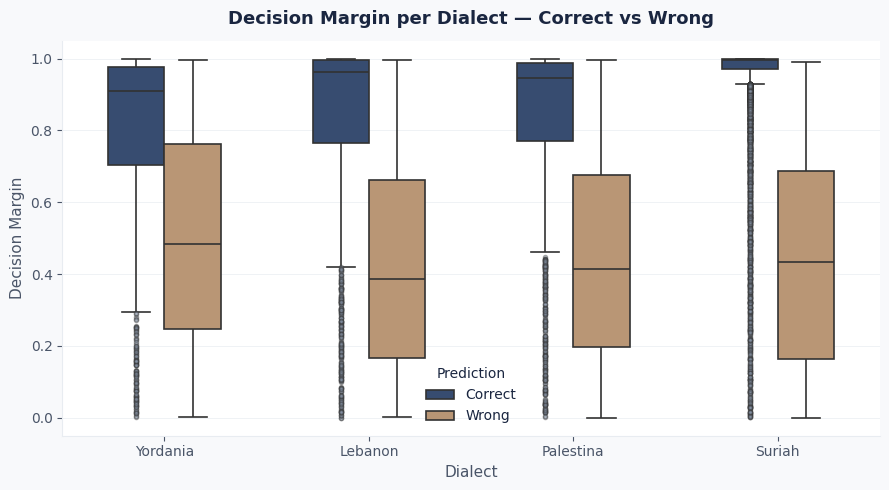

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_dbscansmote_margin_exact_metrics.csv

Processing: lightgbm_balanced_weighted
✅ [lightgbm_balanced_weighted] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_balanced_weighted_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_balanced_weighted_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,770

ERROR SUMMARY
true_label pred_label     error_category  count
    Suriah   Yordania  medium_conf_wrong     91
    Suriah  Palestina  medium_conf_wrong     88
  Yordania  Palestina  medium_conf_wrong     80
    Suriah    Lebanon  medium_conf_wrong     76
   Lebanon  Palestina  medium_conf_wrong     66
 Palestina   Yordania  medium_conf_wrong     66
 Palestina    Lebanon  medium_conf_wrong     64
    Suriah    Lebanon     too_short_<30c     62
    Suriah    Lebanon     too_short_<=4w     60
   Lebanon     Suriah  medium_conf_wrong     57
 Palestina     Suriah  mediu

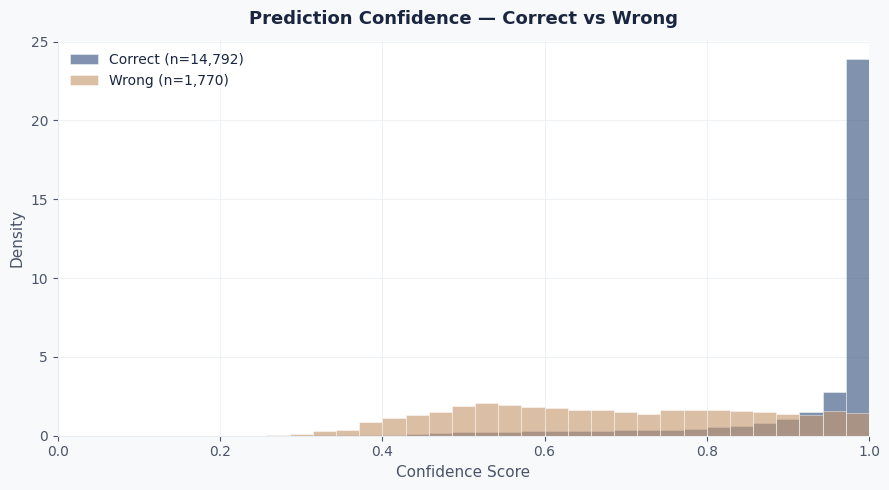

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_balanced_weighted_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_balanced_weighted_entropy_per_class.png


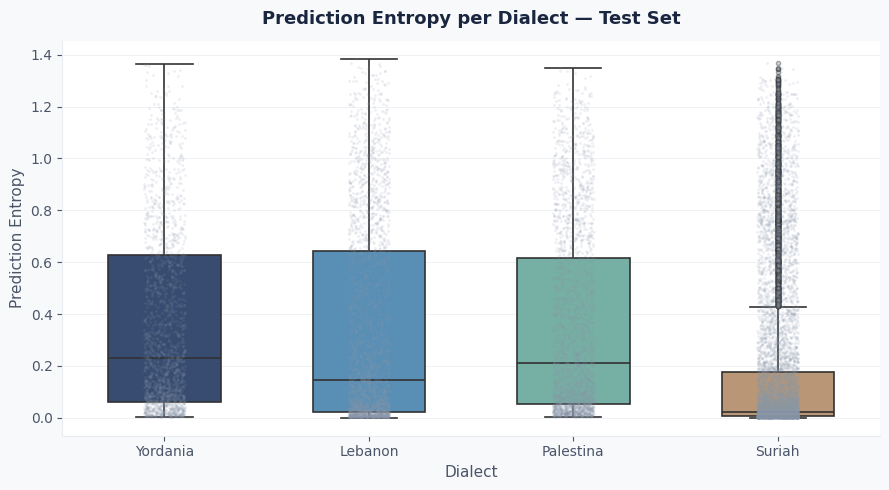

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_balanced_weighted_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_balanced_weighted_margin_analysis.png


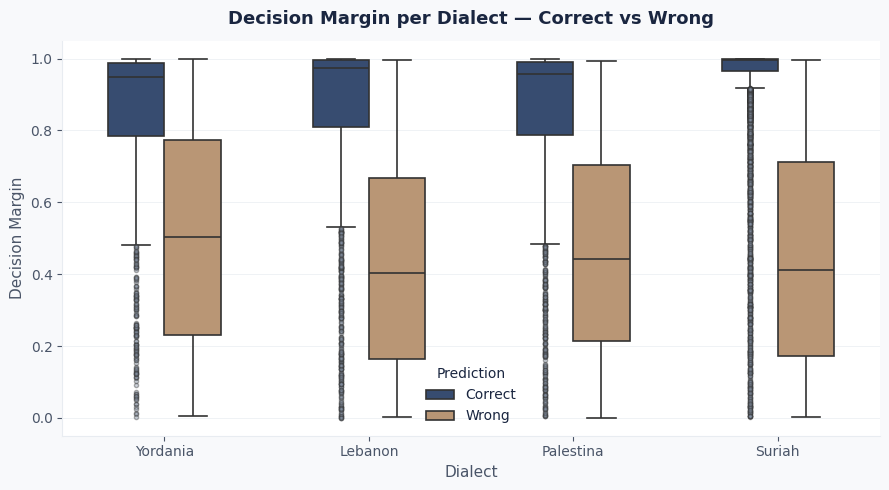

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_balanced_weighted_margin_exact_metrics.csv

Processing: lightgbm_astra_radiant
⚙️ [lightgbm_astra_radiant] CSV belum ada; predicting trained model.
📦 Loading trained model: artifacts/lightgbm_astra_radiant/model/model_lightgbm_astra_radiant.pkl
✅ Generated: 16,562 rows, 1,706 errors
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_astra_radiant_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_astra_radiant_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,706

ERROR SUMMARY
true_label pred_label     error_category  count
   Lebanon     Suriah  medium_conf_wrong     83
  Yordania  Palestina  medium_conf_wrong     81
 Palestina    Lebanon  medium_conf_wrong     71
 Palestina     Suriah  medium_conf_wrong     70
    Suriah  Palestina  medium_conf_wrong     64
    Suriah    Lebanon  medium_conf_wrong     61
   Lebanon     Suriah     too_short_<=4w     56
   Lebanon  Palestina  med

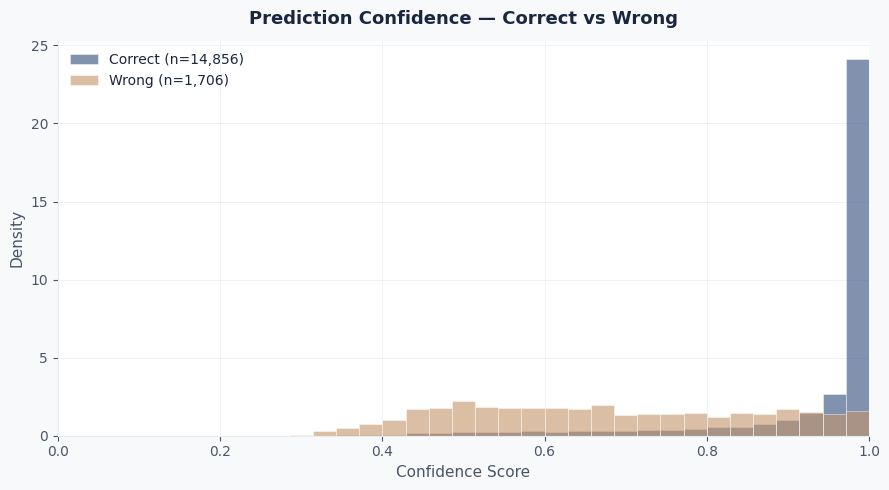

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_astra_radiant_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_astra_radiant_entropy_per_class.png


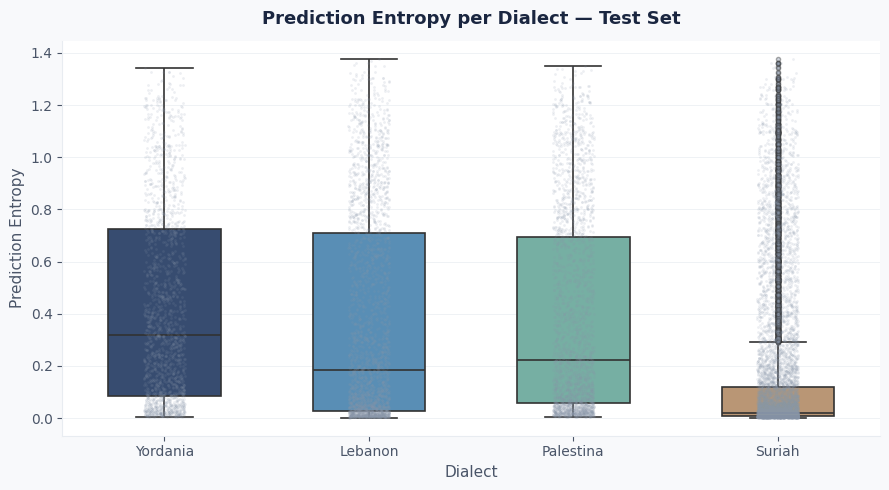

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_astra_radiant_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/lightgbm_astra_radiant_margin_analysis.png


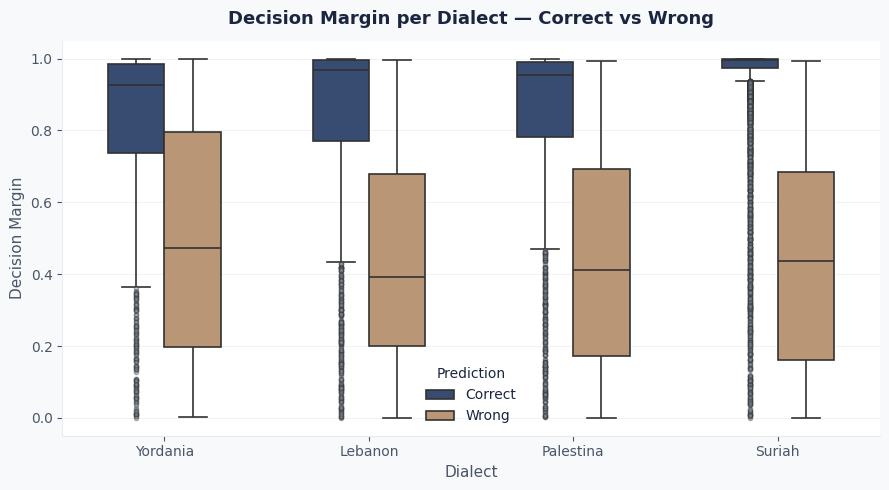

📄 Saved: artifacts/entropy_margin_conf/docs/lightgbm_astra_radiant_margin_exact_metrics.csv

Processing: xgboost_original
✅ [xgboost_original] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_original_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_original_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,722

ERROR SUMMARY
true_label pred_label     error_category  count
   Lebanon     Suriah  medium_conf_wrong     94
 Palestina     Suriah  medium_conf_wrong     84
  Yordania  Palestina  medium_conf_wrong     83
  Yordania     Suriah  medium_conf_wrong     74
    Suriah  Palestina  medium_conf_wrong     64
 Palestina    Lebanon  medium_conf_wrong     63
   Lebanon  Palestina  medium_conf_wrong     62
    Suriah    Lebanon  medium_conf_wrong     62
 Palestina   Yordania  medium_conf_wrong     60
   Lebanon     Suriah     too_short_<=4w     56
    Suriah   Yordania  medium_conf_wrong     47
   Lebanon     Sur

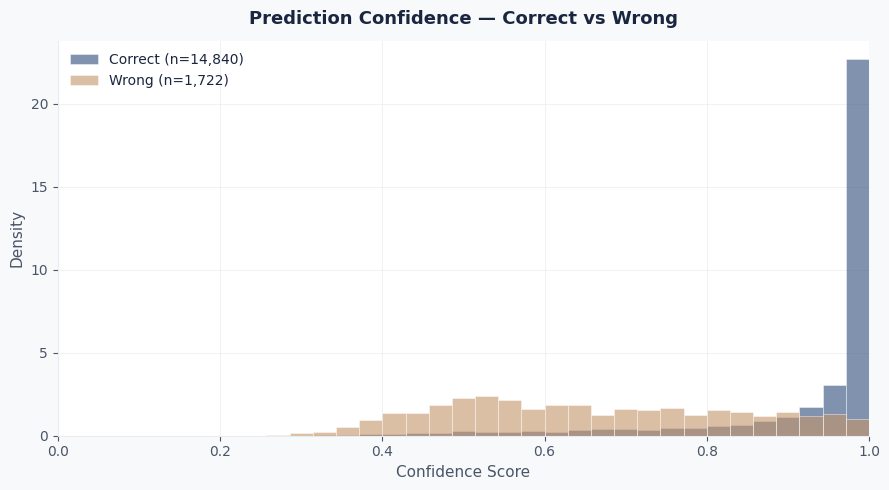

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_original_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_original_entropy_per_class.png


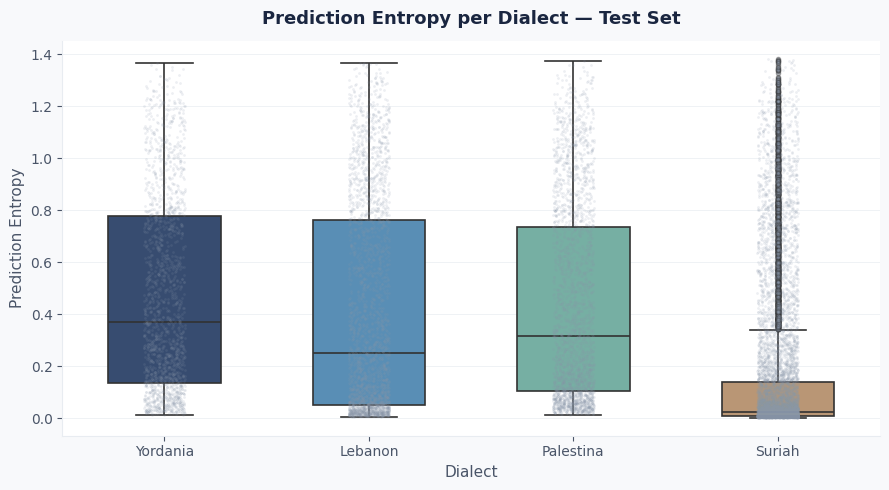

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_original_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_original_margin_analysis.png


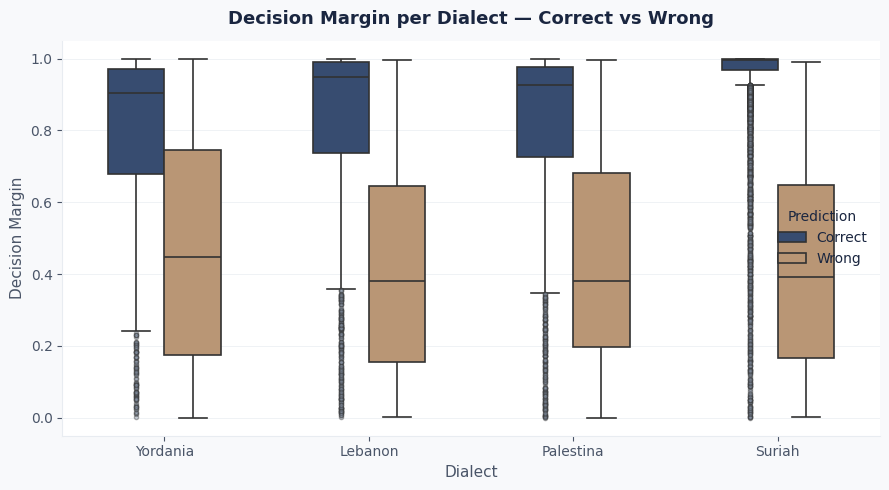

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_original_margin_exact_metrics.csv

Processing: xgboost_smote
✅ [xgboost_smote] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_smote_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_smote_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,715

ERROR SUMMARY
true_label pred_label     error_category  count
   Lebanon     Suriah  medium_conf_wrong     85
  Yordania  Palestina  medium_conf_wrong     80
 Palestina     Suriah  medium_conf_wrong     79
  Yordania     Suriah  medium_conf_wrong     70
    Suriah    Lebanon  medium_conf_wrong     66
    Suriah  Palestina  medium_conf_wrong     66
 Palestina   Yordania  medium_conf_wrong     61
 Palestina    Lebanon  medium_conf_wrong     59
   Lebanon  Palestina  medium_conf_wrong     58
   Lebanon     Suriah     too_short_<=4w     55
    Suriah   Yordania  medium_conf_wrong     48
   Lebanon     Suriah     too_short_

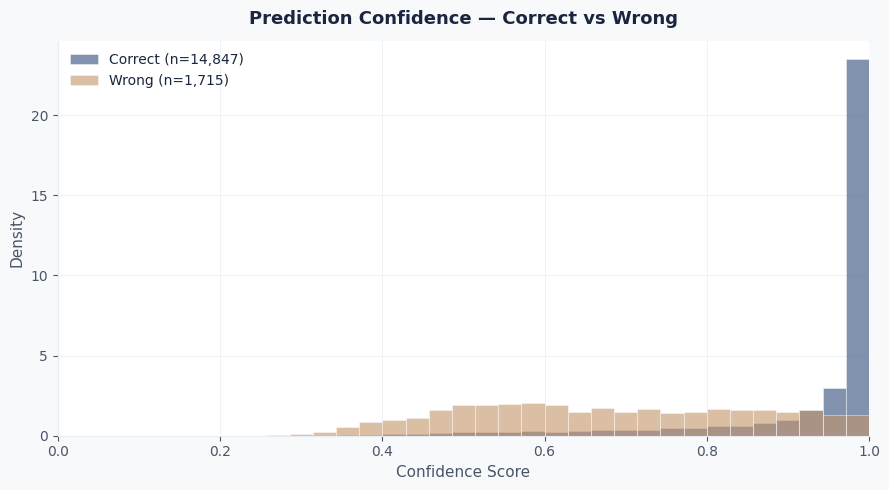

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_smote_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_smote_entropy_per_class.png


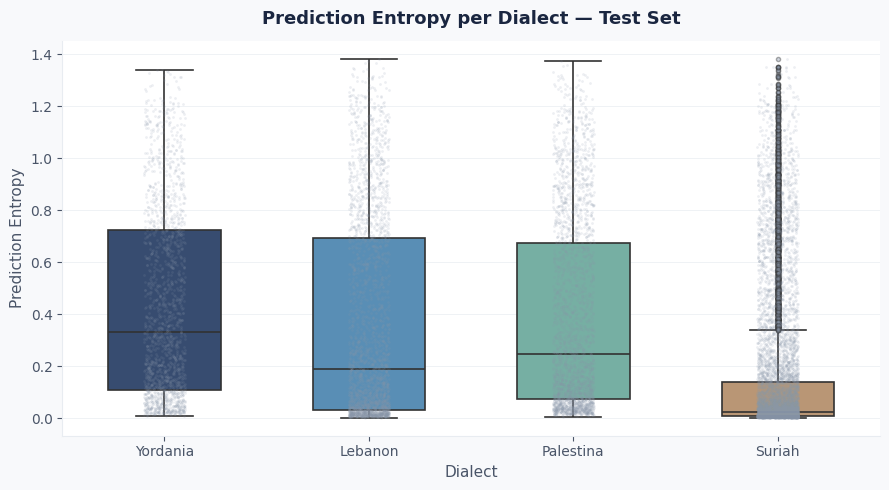

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_smote_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_smote_margin_analysis.png


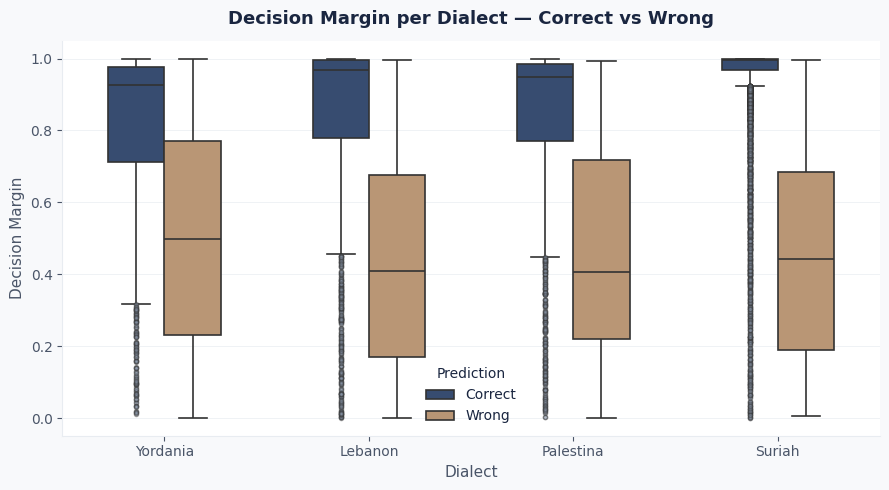

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_smote_margin_exact_metrics.csv

Processing: xgboost_knsmote
✅ [xgboost_knsmote] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_knsmote_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_knsmote_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,729

ERROR SUMMARY
true_label pred_label     error_category  count
   Lebanon     Suriah  medium_conf_wrong     88
 Palestina     Suriah  medium_conf_wrong     85
  Yordania  Palestina  medium_conf_wrong     75
    Suriah  Palestina  medium_conf_wrong     66
 Palestina    Lebanon  medium_conf_wrong     65
    Suriah    Lebanon  medium_conf_wrong     59
  Yordania     Suriah  medium_conf_wrong     59
   Lebanon     Suriah     too_short_<=4w     57
 Palestina   Yordania  medium_conf_wrong     54
   Lebanon  Palestina  medium_conf_wrong     52
    Suriah   Yordania  medium_conf_wrong     48
  Yordania  Palestina    high_c

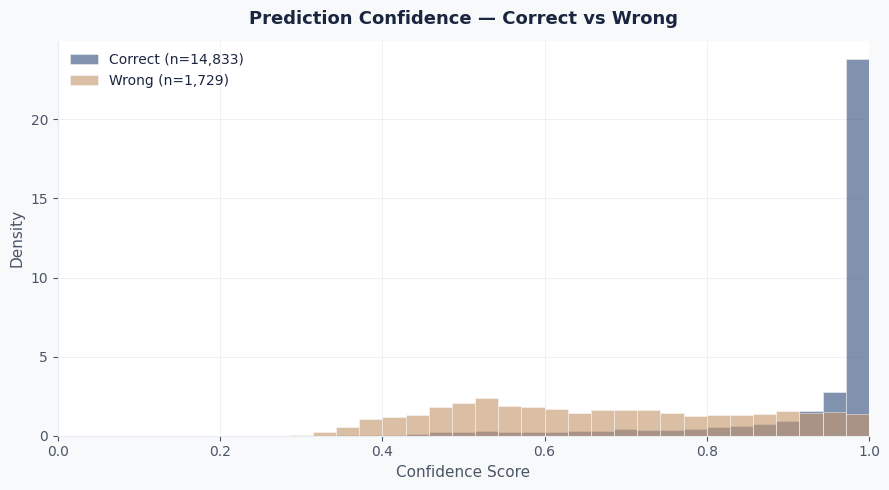

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_knsmote_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_knsmote_entropy_per_class.png


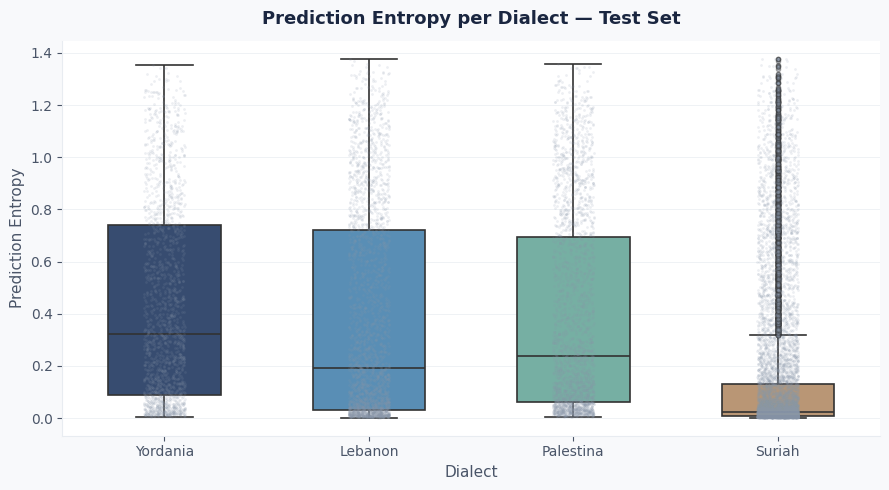

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_knsmote_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_knsmote_margin_analysis.png


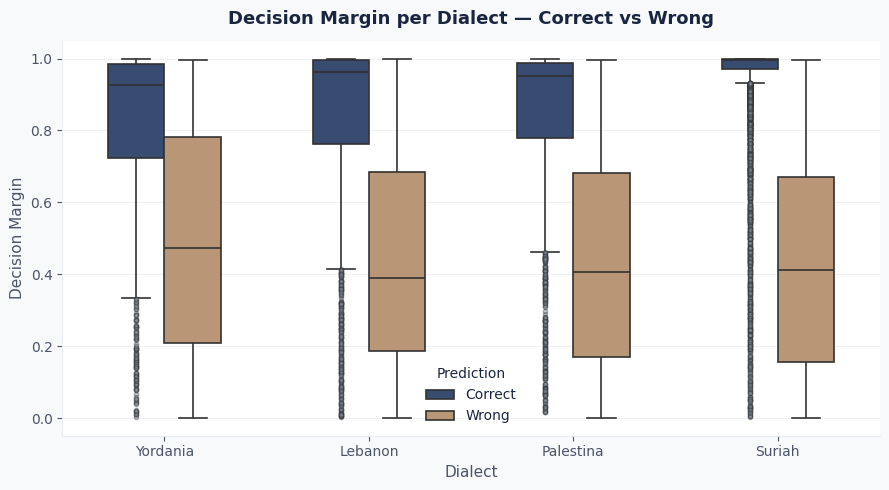

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_knsmote_margin_exact_metrics.csv

Processing: xgboost_dbscansmote
✅ [xgboost_dbscansmote] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_dbscansmote_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_dbscansmote_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,715

ERROR SUMMARY
true_label pred_label     error_category  count
   Lebanon     Suriah  medium_conf_wrong     84
  Yordania  Palestina  medium_conf_wrong     81
 Palestina     Suriah  medium_conf_wrong     78
  Yordania     Suriah  medium_conf_wrong     74
    Suriah  Palestina  medium_conf_wrong     68
 Palestina   Yordania  medium_conf_wrong     60
    Suriah    Lebanon  medium_conf_wrong     60
 Palestina    Lebanon  medium_conf_wrong     60
   Lebanon     Suriah     too_short_<=4w     58
    Suriah   Yordania  medium_conf_wrong     53
   Lebanon  Palestina  medium_conf_wrong     53
 Palestina   

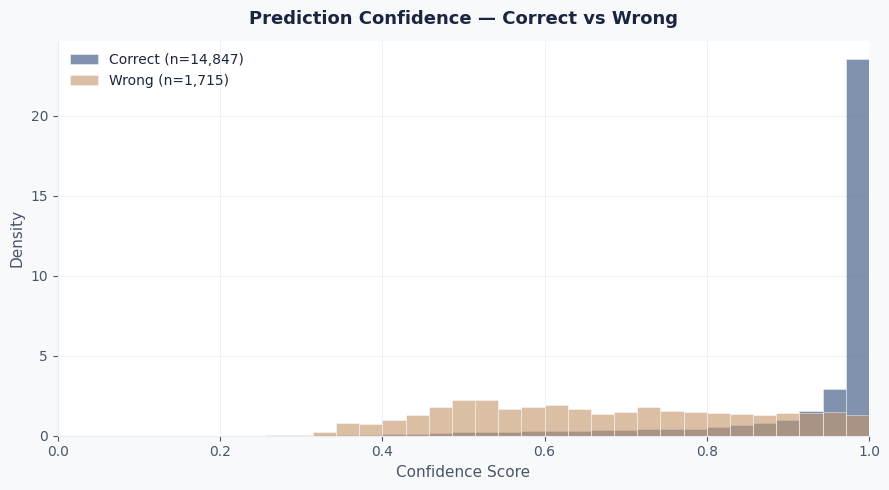

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_dbscansmote_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_dbscansmote_entropy_per_class.png


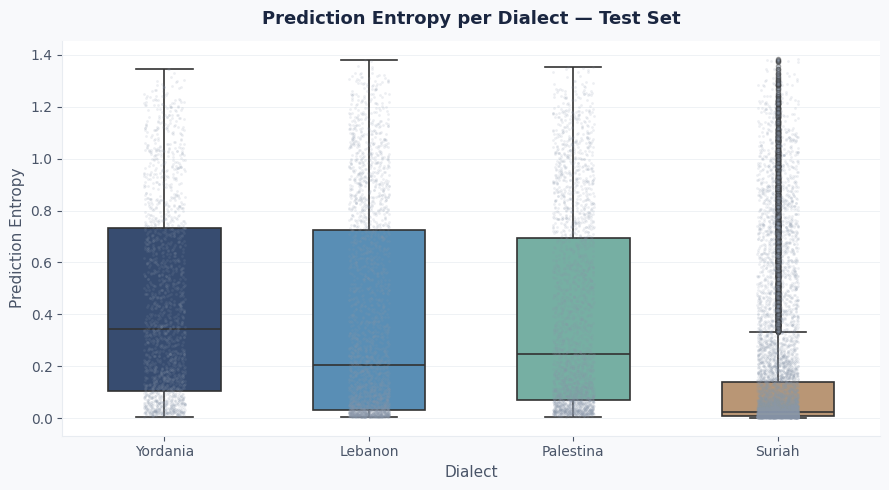

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_dbscansmote_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_dbscansmote_margin_analysis.png


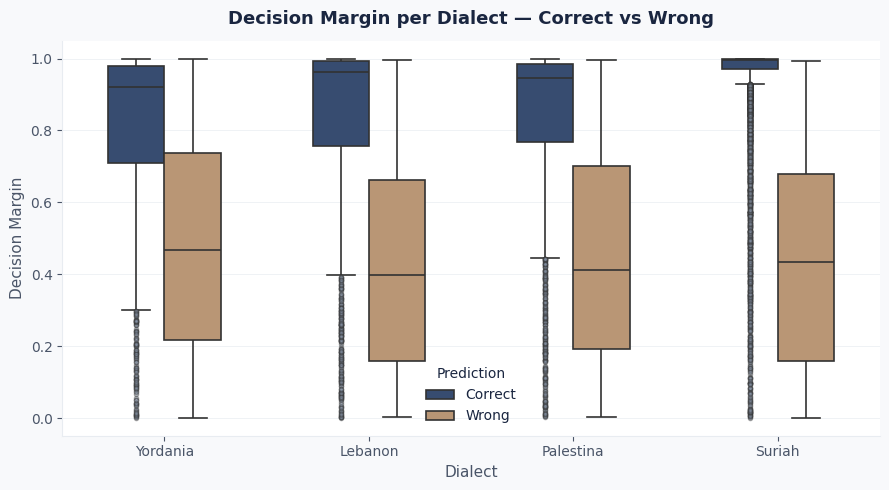

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_dbscansmote_margin_exact_metrics.csv

Processing: xgboost_balanced_weighted
✅ [xgboost_balanced_weighted] loading existing CSV.
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_balanced_weighted_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_balanced_weighted_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,765

ERROR SUMMARY
true_label pred_label     error_category  count
    Suriah   Yordania  medium_conf_wrong     92
    Suriah  Palestina  medium_conf_wrong     90
  Yordania  Palestina  medium_conf_wrong     81
    Suriah    Lebanon  medium_conf_wrong     71
   Lebanon  Palestina  medium_conf_wrong     65
    Suriah    Lebanon     too_short_<=4w     62
 Palestina   Yordania  medium_conf_wrong     62
 Palestina    Lebanon  medium_conf_wrong     61
    Suriah    Lebanon     too_short_<30c     60
 Palestina     Suriah  medium_conf_wrong     51
 Palestina    Lebanon     too_sho

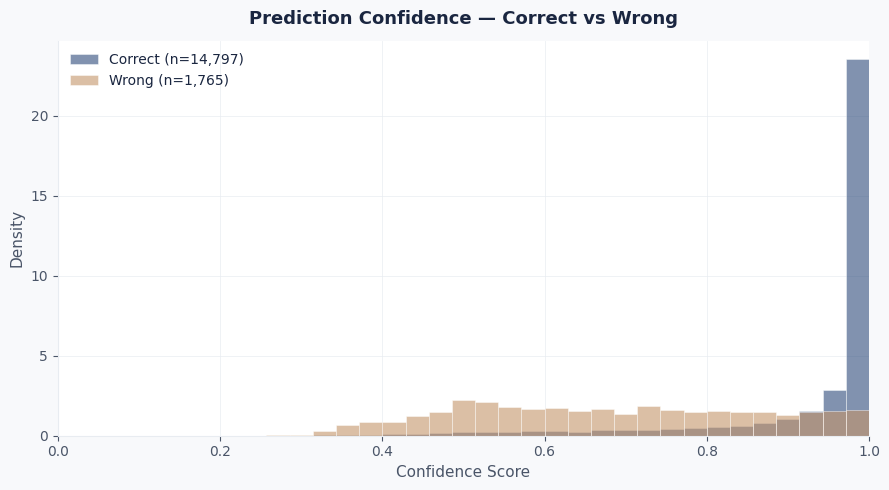

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_balanced_weighted_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_balanced_weighted_entropy_per_class.png


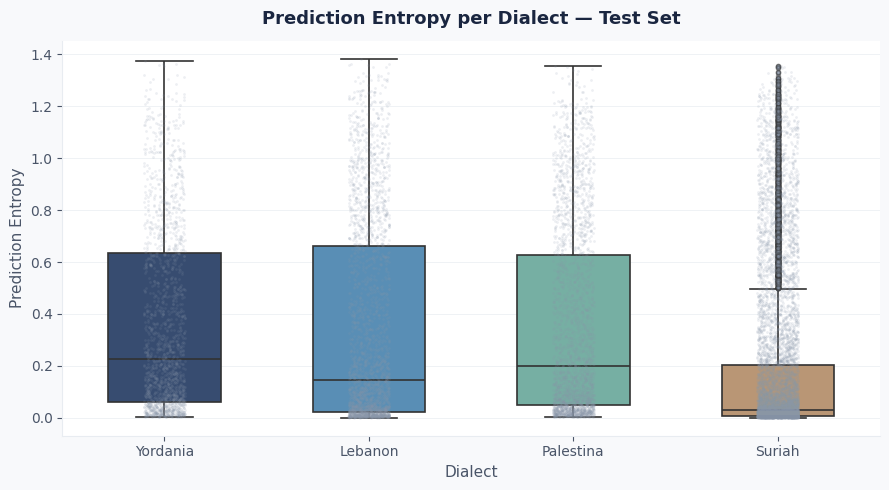

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_balanced_weighted_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_balanced_weighted_margin_analysis.png


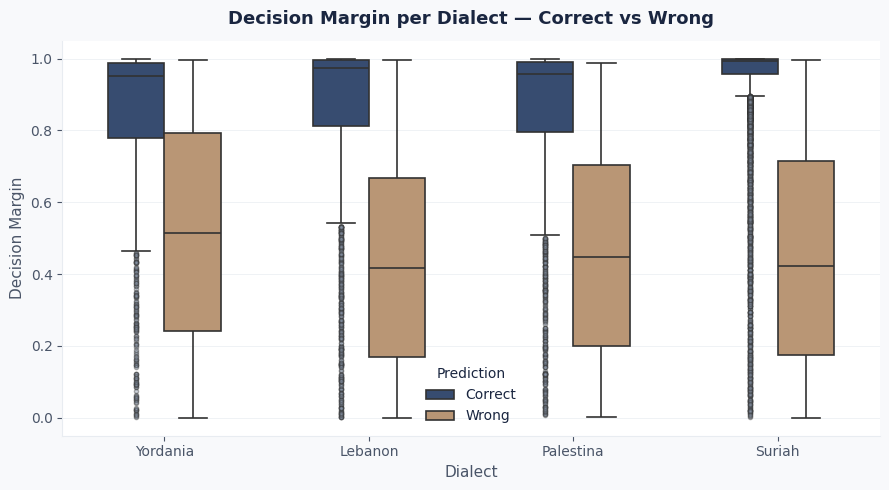

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_balanced_weighted_margin_exact_metrics.csv

Processing: xgboost_astra_radiant
⚙️ [xgboost_astra_radiant] CSV belum ada; predicting trained model.
📦 Loading trained model: artifacts/xgboost_astra_radiant/model/model_xgboost_astra_radiant.pkl
✅ Generated: 16,562 rows, 1,695 errors
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_astra_radiant_error_analysis_full.csv
📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_astra_radiant_error_analysis_errors_only.csv
Loaded full data: 16,562
Loaded errors   : 1,695

ERROR SUMMARY
true_label pred_label     error_category  count
   Lebanon     Suriah  medium_conf_wrong     89
 Palestina     Suriah  medium_conf_wrong     80
  Yordania  Palestina  medium_conf_wrong     76
    Suriah  Palestina  medium_conf_wrong     69
  Yordania     Suriah  medium_conf_wrong     62
 Palestina   Yordania  medium_conf_wrong     61
 Palestina    Lebanon  medium_conf_wrong     59
   Lebanon     Suriah     too_sho

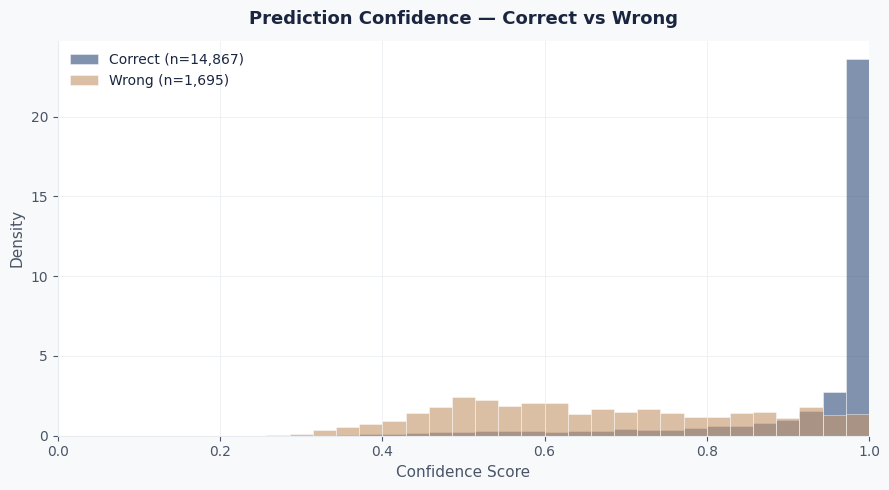

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_astra_radiant_confidence_histogram_data.csv

Generating Entropy Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_astra_radiant_entropy_per_class.png


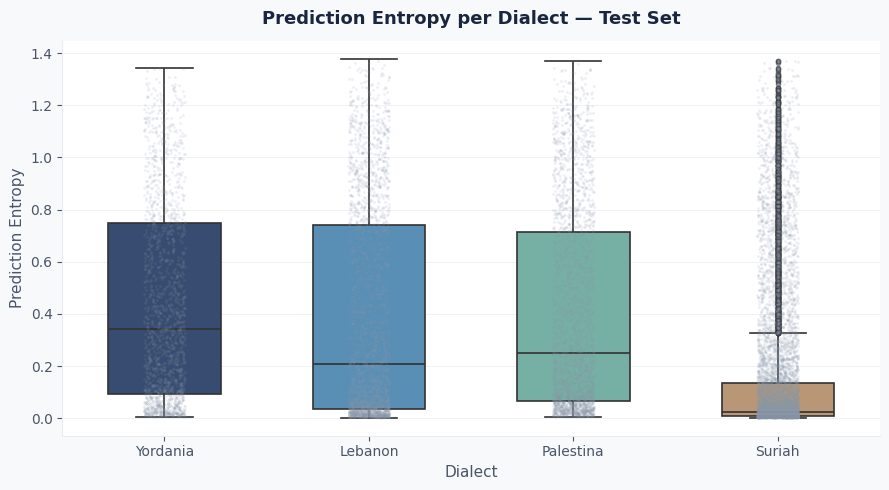

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_astra_radiant_entropy_exact_metrics.csv

Generating Margin Analysis...
🖼️ Saved: artifacts/entropy_margin_conf/image/xgboost_astra_radiant_margin_analysis.png


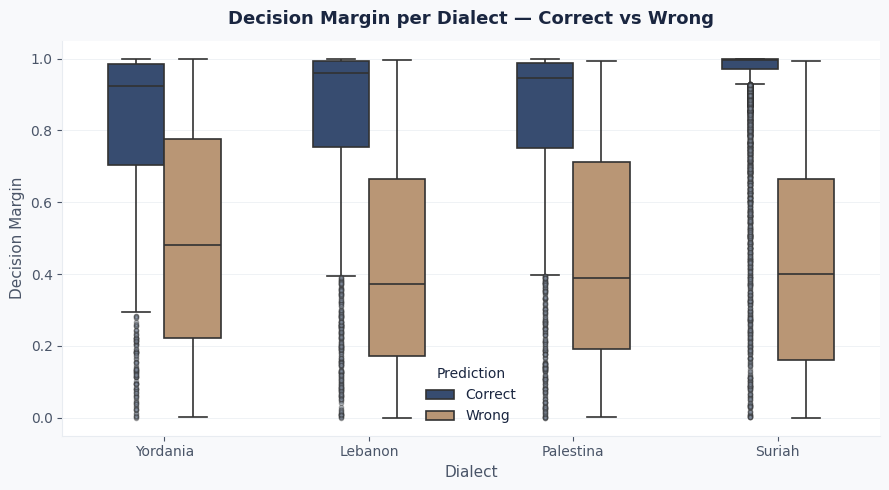

📄 Saved: artifacts/entropy_margin_conf/docs/xgboost_astra_radiant_margin_exact_metrics.csv

ANALYSIS COMPLETE
Processed: 12
Skipped  : 0
Image dir: artifacts/entropy_margin_conf/image
Docs dir : artifacts/entropy_margin_conf/docs


In [7]:
# 7. MAIN PIPELINE
def main():
    features_module = load_features_module()

    # --------------------------------------------------------
    # Preflight: cari komposisi yang belum memiliki CSV lengkap
    # baik pada output baru maupun direktori lama.
    # --------------------------------------------------------
    missing_csv = []

    for komposisi in KOMPOSISI_LIST:
        input_docs_dir = os.path.join(INPUT_ROOT, komposisi, "docs")
        available = (
            csv_pair_exists(OUTPUT_DOCS_DIR, komposisi)
            or csv_pair_exists(input_docs_dir, komposisi)
        )
        if not available:
            missing_csv.append(komposisi)

    print("\n" + "=" * 80)
    print("CSV PREFLIGHT")
    print("=" * 80)

    if missing_csv:
        print(f"⚠️ {len(missing_csv)} komposisi belum memiliki pasangan CSV:")
        for komposisi in missing_csv:
            print("  -", komposisi)

        print("\n⚙️ Preparing shared test data once...")
        analysis_context = prepare_analysis_context(features_module)
    else:
        print("✅ Seluruh CSV tersedia; feature preparation tidak diperlukan.")
        analysis_context = None

    processed = []
    skipped = []

    # --------------------------------------------------------
    # Semua komposisi melewati fungsi yang sama.
    # --------------------------------------------------------
    for komposisi in KOMPOSISI_LIST:
        print("\n" + "=" * 80)
        print("Processing:", komposisi)
        print("=" * 80)

        df_export, df_errors = get_or_create_error_analysis(
            komposisi,
            analysis_context=analysis_context,
        )

        if df_export is None or df_errors is None:
            skipped.append(komposisi)
            continue

        print(f"Loaded full data: {len(df_export):,}")
        print(f"Loaded errors   : {len(df_errors):,}")

        print_error_summary(df_errors)
        process_confidence(df_export, komposisi)
        process_entropy(df_export, komposisi)
        process_margin(df_export, komposisi)

        processed.append(komposisi)

    print("\n" + "=" * 80)
    print("ANALYSIS COMPLETE")
    print("=" * 80)
    print("Processed:", len(processed))
    print("Skipped  :", len(skipped))
    print("Image dir:", OUTPUT_IMAGE_DIR)
    print("Docs dir :", OUTPUT_DOCS_DIR)

    if skipped:
        print("\nSkipped compositions:")
        for komposisi in skipped:
            print("  ⚠️", komposisi)

    return {
        "processed": processed,
        "skipped": skipped,
        "image_dir": OUTPUT_IMAGE_DIR,
        "docs_dir": OUTPUT_DOCS_DIR,
    }


run_summary = main()